<a href="https://colab.research.google.com/github/CooL-Legend/CSCI544-DLM/blob/adi/notebooks/gsm8k/Experiment_0_Baseline_Test_Dev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>


# Experiment 0: Baseline Test — Dev

Fixed-budget MEDAL versus greedy confidence, greedy entropy, and the exact MEDAL completion decoder without search.

Default: **5 training questions**, **Lc=5**, search caps **512, 1024, 2048**. Greedy baselines use T=0; MEDAL and its matched no-search control use T=1. All methods use 256 output positions and the same three-step decomposition prompt with the fixed pens and muffins examples. C=3 is a cached shortlist, not a stopping condition.

Search excludes EOS/EOT. Completion allows them, fills every position, and scores only the prefix before the first terminator. Fallback-generated answers count normally. The quota comparison is optional and uses the same depth.

Run top-to-bottom on an L4/A100 Colab GPU. The six conditions load one model in one subprocess. Artifacts and a frozen manifest persist on Drive; preview cells read the exact saved run.

The GitHub checkout must contain the E0 implementation. Before it is pushed, choose `SOURCE_MODE="upload"` and upload the delivered `experiment_0_colab_source.zip`.

See the [implementation README](../../docs/experiment_0/README.md) for the exact protocol, code map, CLI, metrics, artifact fields, and validation runbook.


## 1. Verify GPU

In [7]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError("Select an L4 or A100 GPU runtime, then reconnect.")
gpu = torch.cuda.get_device_properties(0)
print(f"GPU: {gpu.name} | GPU memory: {gpu.total_memory / 2**30:.1f} GiB")
if gpu.total_memory < 20 * 2**30:
    raise RuntimeError("This notebook uses unquantized BF16 weights. Choose an L4/A100 runtime with more GPU memory; a 16 GB T4 is too small for this setup.")
if not torch.cuda.is_bf16_supported():
    raise RuntimeError("This GPU does not support the configured BF16 inference.")


GPU: NVIDIA L4 | GPU memory: 22.0 GiB


## 2. Get the source
Use the private repository on `adi` or upload the source bundle. Existing checkout changes are never discarded.

In [8]:
SOURCE_MODE = "github"  # Change to "upload" to use the delivered source ZIP.

from pathlib import Path
import getpass
import os
import subprocess
import sys
import tempfile

REPOSITORY = "CooL-Legend/CSCI544-DLM"
BRANCH = "adi"
REPO_URL = f"https://github.com/{REPOSITORY}.git"
REPO_DIR = Path("/content/CSCI544-DLM")

def run_git(args, token=None):
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}
    with tempfile.TemporaryDirectory() as tmp:
        if token:
            askpass = Path(tmp) / "askpass.py"
            askpass.write_text(
                "#!/usr/bin/env python3\nimport os, sys\n"
                "print('x-access-token' if 'username' in sys.argv[1].lower() else os.environ['COLAB_GH_TOKEN'])\n"
            )
            askpass.chmod(0o700)
            env.update(GIT_ASKPASS=str(askpass), COLAB_GH_TOKEN=token)
        return subprocess.run(["git", "-c", "credential.helper=", *args], env=env, capture_output=True, text=True)

def remote_git(args):
    result = run_git(args)
    if result.returncode:
        from google.colab import userdata
        try:
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
        if not token:
            token = getpass.getpass("GitHub token with read access to this private repository: ")
        try:
            result = run_git(args, token)
        finally:
            del token
    if result.returncode:
        raise RuntimeError(result.stderr.strip() or "GitHub clone/update failed.")

def ensure_checkout():
    def local_git(*args):
        return subprocess.check_output(["git", "-C", str(REPO_DIR), *args], text=True).strip()

    if REPO_DIR.exists():
        if not (REPO_DIR / ".git").is_dir():
            raise RuntimeError(f"{REPO_DIR} exists but is not a Git checkout. Choose another REPO_DIR.")
        if local_git("remote", "get-url", "origin") != REPO_URL:
            raise RuntimeError("The existing checkout belongs to a different repository.")
        if local_git("status", "--porcelain"):
            raise RuntimeError("The checkout has local changes. Save them or choose another REPO_DIR before updating.")
        fetch_specs = local_git("config", "--get-all", "remote.origin.fetch").splitlines()
        branch_ref = f"refs/heads/{BRANCH}:refs/remotes/origin/{BRANCH}"
        if not any(spec.lstrip("+") in (branch_ref, "refs/heads/*:refs/remotes/origin/*") for spec in fetch_specs):
            local_git("remote", "set-branches", "--add", "origin", BRANCH)
        remote_git(["-C", str(REPO_DIR), "fetch", "origin", branch_ref])
        exists = subprocess.run(["git", "-C", str(REPO_DIR), "show-ref", "--verify", "--quiet", f"refs/heads/{BRANCH}"]).returncode == 0
        if exists:
            local_git("switch", BRANCH)
        else:
            local_git("switch", "--create", BRANCH, "--track", f"origin/{BRANCH}")
        local_git("merge", "--ff-only", f"origin/{BRANCH}")
    else:
        remote_git(["clone", "--branch", BRANCH, "--single-branch", REPO_URL, str(REPO_DIR)])
    if local_git("branch", "--show-current") != BRANCH or local_git("rev-parse", "HEAD") != local_git("rev-parse", f"origin/{BRANCH}"):
        raise RuntimeError("The checkout differs from origin/adi. Review local commits before running experiments.")
    print(f"Code ready: {REPO_DIR} | branch: {BRANCH} | commit: {local_git('rev-parse', '--short', 'HEAD')}")

if SOURCE_MODE == "github":
    ensure_checkout()
elif SOURCE_MODE == "upload":
    # The delivered source ZIP works before these changes have been pushed to adi.
    from google.colab import files
    import io
    import uuid
    import zipfile
    uploaded = files.upload()
    archives = [name for name in uploaded if name.endswith(".zip")]
    if len(archives) != 1:
        raise RuntimeError("Upload exactly one experiment_0_colab_source.zip archive.")
    REPO_DIR = Path("/content/CSCI544-DLM-e0") / uuid.uuid4().hex[:8]
    REPO_DIR.mkdir(parents=True)
    with zipfile.ZipFile(io.BytesIO(uploaded[archives[0]])) as archive:
        for member in archive.infolist():
            target = (REPO_DIR / member.filename).resolve()
            if not target.is_relative_to(REPO_DIR.resolve()):
                raise RuntimeError("Unsafe source archive path.")
        archive.extractall(REPO_DIR)
    del uploaded
    print("Uploaded E0 source:", REPO_DIR)
else:
    raise ValueError("SOURCE_MODE must be github or upload.")
if not (REPO_DIR / "scripts/experiment_0_baseline_test.py").is_file():
    raise RuntimeError("E0 is not on this checkout yet. Set SOURCE_MODE='upload' and use the delivered source ZIP, or publish the E0 commit to adi.")


Code ready: /content/CSCI544-DLM | branch: adi | commit: 5bf9f37


## 3. Install LLaDA dependencies

In [9]:
subprocess.run([
    sys.executable, "-m", "pip", "install", "-q",
    "-r", str(REPO_DIR / "requirements/llada-colab.txt"),
], check=True)

# Install our package without replacing Colab's CUDA-enabled PyTorch.
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "-e", str(REPO_DIR)], check=True)
# Refresh editable-package paths in this already-running notebook kernel.
import site
for package_dir in [*site.getsitepackages(), site.getusersitepackages()]:
    site.addsitedir(package_dir)


### Controlled decoder and workflow checks
These tests use tiny models. The CUDA checks validate device handling without downloading LLaDA.

In [10]:
import subprocess
import sys

# Install development requirements
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO_DIR / "requirements/dev.txt")], check=True)

# Run pytest with captured output to diagnose which specific tests or imports are failing
try:
    result = subprocess.run(
        [sys.executable, "-m", "pytest", "-v",
         "tests/decoding/test_experiment_0.py", "tests/decoding/test_mcts_cuda.py",
         "tests/tasks/test_e0_dataset.py", "tests/workflows/test_experiment_0.py"],
        cwd=REPO_DIR,
        capture_output=True,
        text=True,
        check=True
    )
    print(result.stdout)
except subprocess.CalledProcessError as e:
    print("--- TEST RUN FAILED ---")
    print("STDOUT:")
    print(e.stdout)
    print("STDERR:")
    print(e.stderr)
    raise e

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/CSCI544-DLM
configfile: pyproject.toml
plugins: typeguard-4.6.0, platformdirs-4.13.3, anyio-4.15.1, langsmith-0.14.11
collecting ... collected 28 items

tests/decoding/test_experiment_0.py::test_confidence_and_entropy_choose_different_positions_without_extra_forwards PASSED [  3%]
tests/decoding/test_experiment_0.py::test_exclusions_refill_topk_without_changing_distribution_statistics PASSED [  7%]
tests/decoding/test_experiment_0.py::test_budget_continues_beyond_three_candidates_and_has_zero_candidate_scoring_nfes PASSED [ 10%]
tests/decoding/test_experiment_0.py::test_shortlists_and_fallback_are_distinct_from_quota_shortfalls[1-root-0] PASSED [ 14%]
tests/decoding/test_experiment_0.py::test_shortlists_and_fallback_are_distinct_from_quota_shortfalls[2-deepest_evaluated-0] PASSED [ 17%

## 4. Mount Drive and select cache locations

In [11]:
from google.colab import drive
import importlib

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive/CSCI544-DLM")
MODEL_FAMILY = "llada"
from dlm_project.models import profiles as model_profiles
from dlm_project.experiments import paths as experiment_paths
importlib.reload(model_profiles)
importlib.reload(experiment_paths)
profile = model_profiles.get_profile(MODEL_FAMILY)
MODEL_NAME = profile["repo_id"].split("/")[-1]
DRIVE_MODEL_DIR = DRIVE_ROOT / "models" / MODEL_NAME
RUNTIME_MODEL_DIR = Path("/content/models") / MODEL_NAME
COPY_MODEL_TO_RUNTIME = True
EXPERIMENT_TIMEZONE = "America/Los_Angeles"

DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
os.environ["HF_HUB_CACHE"] = str(DRIVE_ROOT / "cache/hub")
os.environ["HF_DATASETS_CACHE"] = str(DRIVE_ROOT / "cache/datasets")
MODEL_PATH = RUNTIME_MODEL_DIR if COPY_MODEL_TO_RUNTIME else DRIVE_MODEL_DIR
print("Persistent model:", DRIVE_MODEL_DIR)
print("Experiment root:", DRIVE_ROOT / profile["label"] / "GSM8K")


Mounted at /content/drive
Persistent model: /content/drive/MyDrive/CSCI544-DLM/models/LLaDA-8B-Instruct
Experiment root: /content/drive/MyDrive/CSCI544-DLM/LLaDA/GSM8K


## 5. Experiment controls
The model revision and prompt are shared. Search caps count root and child forwards; completion is additional. Small development/evaluation runs select prefixes of fixed 5/20-question pools.

In [12]:
import yaml

STAGE = "dev"
NUM_SAMPLES = 5
INIT_TOKENS = 5  # Use 7 for an explicitly labelled extended evaluation.
SEARCH_BUDGETS = [512, 1024, 2048]
RUN_QUOTA_COMPARISON = False

cfg = yaml.safe_load((REPO_DIR / "configs/gsm8k/experiment_0.yaml").read_text())
cfg["model"].update(model_path=str(MODEL_PATH), device="cuda", local_files_only=True)
cfg["data"].update(cache_dir=os.environ["HF_DATASETS_CACHE"], num_samples=NUM_SAMPLES)
cfg["evaluation"].update(stage=STAGE, search_mode="budget", search_budgets=SEARCH_BUDGETS)
cfg["decoding"]["mcts"]["init_tokens"] = INIT_TOKENS
cfg["experiment_root"] = str(DRIVE_ROOT)
cfg["experiment_timezone"] = EXPERIMENT_TIMEZONE
E0_MANIFEST = DRIVE_ROOT / "manifests/gsm8k_e0.json"
E0_CONFIG = Path("/content") / f"experiment-0-{STAGE}.yaml"
E0_CONFIG.write_text(yaml.safe_dump(cfg, sort_keys=False))
print(yaml.safe_dump(cfg, sort_keys=False))
print("Model revision:", profile["revision"])
print("Frozen E0 manifest:", E0_MANIFEST)


model:
  family: llada
  model_path: /content/models/LLaDA-8B-Instruct
  device: cuda
  dtype: bfloat16
  local_files_only: true
data:
  revision: null
  sample_seed: 1
  cache_dir: /content/drive/MyDrive/CSCI544-DLM/cache/datasets
  num_samples: 5
prompt:
  medal_decomposition: false
  template: 'Decompose the question into three steps and solve the math problem following
    the examples.

    State the goal of each step clearly.

    Show your final numerical answer after ####.


    Example 1:

    Problem: A shop has 12 pens. It buys 4 packs containing 6 pens each and gives
    away 9 pens. How many pens remain?


    1. Identify how many pens the shop initially has and how many additional pens
    it buys.

    2. Calculate the total number of pens after the purchase.

    3. Subtract the pens given away to find the remaining quantity.

    #### 27


    Example 2:

    Problem: A bakery makes 48 muffins. It sells half of them in the morning and another
    8 in the afternoon. Ho

## 6. Cache the pinned model

In [13]:
command = [sys.executable, "-u", str(REPO_DIR / "scripts/cache_model.py"), "--model", MODEL_FAMILY, "--drive-dir", str(DRIVE_MODEL_DIR)]
if COPY_MODEL_TO_RUNTIME:
    command += ["--runtime-dir", str(RUNTIME_MODEL_DIR)]
subprocess.run(command, check=True)


CompletedProcess(args=['/usr/bin/python3', '-u', '/content/CSCI544-DLM/scripts/cache_model.py', '--model', 'llada', '--drive-dir', '/content/drive/MyDrive/CSCI544-DLM/models/LLaDA-8B-Instruct', '--runtime-dir', '/content/models/LLaDA-8B-Instruct'], returncode=0)

## 7. Run the six primary conditions
Output streams per completed condition. Each budget uses a fresh tree. Search stops at B or frontier exhaustion and always selects an available state for completion.

In [14]:
import json
import subprocess
import sys
import uuid

E0_RUN_DIR = None
E0_QUOTA_DIR = None
LAST_PARTIAL_RUN_DIR = None

def run_e0(search_mode="budget"):
    global LAST_PARTIAL_RUN_DIR
    LAST_PARTIAL_RUN_DIR = None
    receipt = Path("/content") / f"e0-{STAGE}-{search_mode}-{uuid.uuid4().hex}.json"
    command = [sys.executable, "-u", str(REPO_DIR / "scripts/experiment_0_baseline_test.py"),
               "--config", str(E0_CONFIG), "--stage", STAGE,
               "--num-samples", str(NUM_SAMPLES), "--init-tokens", str(INIT_TOKENS),
               "--search-mode", search_mode, "--search-budgets", *map(str, SEARCH_BUDGETS),
               "--manifest", str(E0_MANIFEST), "--run-manifest", str(receipt)]
    process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, bufsize=1, cwd=REPO_DIR)
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        returncode = process.wait()
    except KeyboardInterrupt:
        process.terminate()
        try:
            process.wait(timeout=10)
        except subprocess.TimeoutExpired:
            process.kill()
            process.wait()
        if receipt.is_file():
            LAST_PARTIAL_RUN_DIR = Path(json.loads(receipt.read_text())["run_dir"])
            print("Partial artifacts:", LAST_PARTIAL_RUN_DIR)
        raise
    if receipt.is_file():
        saved = json.loads(receipt.read_text())
        LAST_PARTIAL_RUN_DIR = Path(saved["run_dir"])
    if returncode:
        print("Partial artifacts:", LAST_PARTIAL_RUN_DIR)
        raise subprocess.CalledProcessError(returncode, command)
    if not receipt.is_file():
        raise RuntimeError("The E0 process produced no run receipt.")
    if (saved["status"] != "completed" or saved["stage"] != STAGE
            or saved["search_mode"] != search_mode or saved["protocol_version"] != "e0_fixed_budget_v2"):
        raise RuntimeError(f"E0 receipt does not describe this completed invocation: {saved}")
    return Path(saved["run_dir"])

E0_RUN_DIR = run_e0("budget")


E0 artifacts: /content/drive/MyDrive/CSCI544-DLM/LLaDA/GSM8K/experiment_0/dev/budget-lc5/20:10:26:11:56:39
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.

Loading checkpoint shards: 100%|██████████| 6/6 [00:33<00:00,  5.52s/it]
I0000 00:00:1792522707.804753    7690 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792522710.936010    7690 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792522710.936596    7690 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train:2337 | co

KeyboardInterrupt: 

## 8. Accuracy, compute, runtime and search depth
Paired metrics use questions with a terminal outcome under every condition. Partial runs retain observed counts and unfinished-forward costs. Report rebuilding performs no inference.

# Experiment 0: Baseline Test

Stage: **dev** · mode: **budget** · Lc=5 · status: **interrupted** · paired questions: **4/5**.

| Condition | Accuracy % (Wilson 95% CI) | Search NFEs | Completion NFEs | Total NFEs | Decode seconds | Fallback rate |
|---|---:|---:|---:|---:|---:|---:|
| confidence_t0 | 50.000 (15.0–85.0) | 0.000 | 256.000 | 256.000 | 70.189 | 0.000 |
| entropy_t0 | 25.000 (4.6–69.9) | 0.000 | 256.000 | 256.000 | 71.140 | 0.000 |
| medal_no_search_t1 | 0.000 (0.0–49.0) | 0.000 | 256.000 | 256.000 | 72.613 | 0.000 |
| medal_budget_b512 | 0.000 (0.0–49.0) | 512.000 | 251.000 | 763.000 | 218.233 | 0.000 |
| medal_budget_b1024 | 0.000 (0.0–49.0) | 1024.000 | 251.000 | 1275.000 | 365.457 | 0.000 |
| medal_budget_b2048 | 0.000 (0.0–49.0) | 2048.000 | 251.000 | 2299.000 | 659.100 | 0.000 |

NFEs and seconds above are means per paired question. The CSV also includes aggregate NFEs, search/completion runtime, median/p95 runtime, depths, shortlist counts, budget utilization, and termination reasons.

| Search condition | Selected / maximum / average depth | Candidates / shortlist | Budget utilization | Quota failures |
|---|---:|---:|---:|---:|
| medal_budget_b512 | 5.000 / 5.000 / 4.246 | 88.000 / 3.000 | 1.000 | 0 |
| medal_budget_b1024 | 5.000 / 5.000 / 4.530 | 153.000 / 3.000 | 1.000 | 0 |
| medal_budget_b2048 | 5.000 / 5.000 / 4.663 | 285.000 / 3.000 | 1.000 | 0 |

| Search condition | Baseline | Accuracy gain (pp) | Additional mean NFEs | pp per additional NFE |
|---|---|---:|---:|---:|
| medal_budget_b512 | confidence_t0 | -50.000 | 507.000 | -0.099 |
| medal_budget_b512 | entropy_t0 | -25.000 | 507.000 | -0.049 |
| medal_budget_b512 | medal_no_search_t1 | 0.000 | 507.000 | 0.000 |
| medal_budget_b1024 | confidence_t0 | -50.000 | 1019.000 | -0.049 |
| medal_budget_b1024 | entropy_t0 | -25.000 | 1019.000 | -0.025 |
| medal_budget_b1024 | medal_no_search_t1 | 0.000 | 1019.000 | 0.000 |
| medal_budget_b2048 | confidence_t0 | -50.000 | 2043.000 | -0.024 |
| medal_budget_b2048 | entropy_t0 | -25.000 | 2043.000 | -0.012 |
| medal_budget_b2048 | medal_no_search_t1 | 0.000 | 2043.000 | 0.000 |

The T=1 no-search MEDAL control uses the identical downstream decoder and completion seed. Greedy baselines use T=0. Search excludes EOS/EOT; every completion permits them and fills all positions. Scoring uses only the prefix before the first terminator, with the existing strict #### parser.

Fallback outputs count normally. Strict quota failures count as incorrect. Missing/interrupted outcomes are excluded from the paired comparison and remain visible in observed_summary.csv. Unfinished attempt forwards: 0. Model loading, warm-up, tokenization, scoring, artifact writing and reporting are recorded separately in setup.json. Decode timing includes decoder bookkeeping and CUDA synchronization; disk trace writing is outside that interval.

This is the repository's MEDAL reconstruction with the E0 protocol, not a claim of author-code parity.



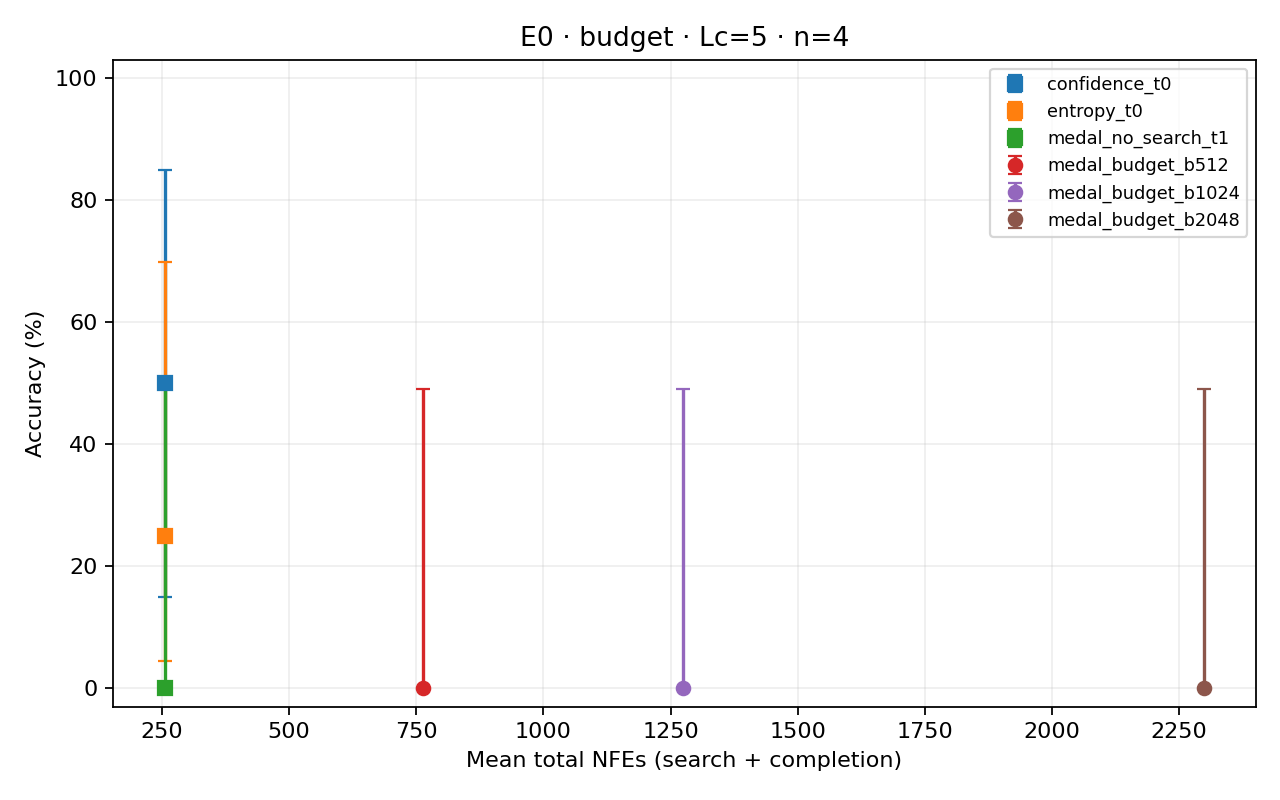

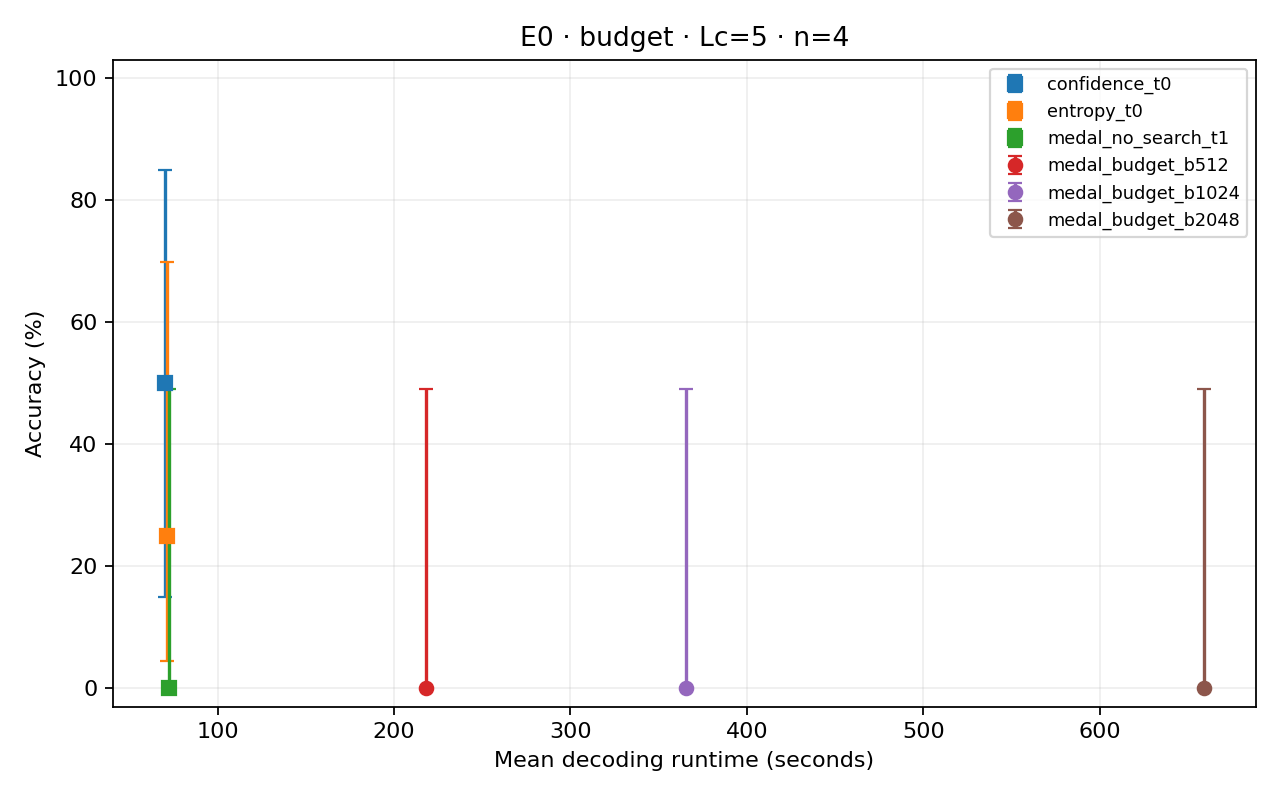

/content/drive/MyDrive/CSCI544-DLM/LLaDA/GSM8K/experiment_0/dev/budget-lc5/20:10:26:11:56:39/report/summary.csv

/content/drive/MyDrive/CSCI544-DLM/LLaDA/GSM8K/experiment_0/dev/budget-lc5/20:10:26:11:56:39/report/observed_summary.csv

/content/drive/MyDrive/CSCI544-DLM/LLaDA/GSM8K/experiment_0/dev/budget-lc5/20:10:26:11:56:39/report/accuracy_gains.csv

/content/drive/MyDrive/CSCI544-DLM/LLaDA/GSM8K/experiment_0/dev/budget-lc5/20:10:26:11:56:39/report/results.csv

Setup and separate overhead timings:
{
  "status": "interrupted",
  "model_load_count": 1,
  "warmup_nfes": 1,
  "tokenization_seconds": 0.009643543999345638,
  "scoring_seconds": 5.587005167000598,
  "artifact_writing_seconds": 3.173834589001217,
  "active_total_nfes": 0,
  "model_loading_seconds": 34.370611962999874,
  "gpu_name": "NVIDIA L4",
  "warmup_seconds": 1.3676150930000404,
  "active_example_id": "train:6679",
  "active_condition": "confidence_t0",
  "active_trace_file": "traces/train_6679_confidence_t0.jsonl",
  "active_decoding_seconds": 0.0,
  "error": "KeyboardInterrupt: E0 subprocess terminated"
}


In [15]:
from IPython.display import display, Markdown, Image, FileLink

REPORT_DIR = E0_RUN_DIR or LAST_PARTIAL_RUN_DIR
if REPORT_DIR is None:
    raise RuntimeError("Run E0 first, or set REPORT_DIR to one saved E0 run directory.")
# Rebuild from saved records only. This subprocess does not load weights or data.
subprocess.run([sys.executable, str(REPO_DIR / "scripts/experiment_0_baseline_test.py"),
                "--report-only", str(REPORT_DIR)], check=True, cwd=REPO_DIR)
display(Markdown((REPORT_DIR / "report/report.md").read_text()))
for name in ["accuracy_vs_total_nfes", "accuracy_vs_runtime"]:
    display(Image(filename=str(REPORT_DIR / f"report/plots/{name}.png")))
for name in ["summary.csv", "observed_summary.csv", "accuracy_gains.csv", "results.csv"]:
    display(FileLink(str(REPORT_DIR / "report" / name)))
print("Setup and separate overhead timings:")
print(json.dumps(json.loads((REPORT_DIR / "setup.json").read_text()), indent=2))


## 9. Inspect saved answers and termination boundaries

In [16]:
from IPython.display import Code

QUESTION_INDEX = 0
records = [json.loads(line) for line in (REPORT_DIR / "predictions.jsonl").read_text().splitlines() if line.strip()]
example_ids = list(dict.fromkeys(row["example_id"] for row in records))
if not 0 <= QUESTION_INDEX < len(example_ids):
    raise ValueError(f"Choose QUESTION_INDEX in 0..{len(example_ids)-1}.")
selected = [row for row in records if row["example_id"] == example_ids[QUESTION_INDEX]]
print(selected[0]["example_id"], selected[0]["question"])
for row in selected:
    print("\n", row["condition"], row["status"], "correct=", row["exact_match"],
          "predicted=", row["predicted_answer"], "expected=", row["reference_answer"])
    print("search/completion/total NFEs:", row["search_nfes"], row["completion_nfes"], row["total_nfes"],
          "selection:", row["selection_source"], "depth:", row["selected_depth"],
          "first EOS/EOT:", row["first_terminator_position"])
    print("Scored prefix:")
    display(Code(row["scoring_text"], language="text"))
    print("Full fixed-length output, including special tokens:")
    display(Code(row["raw_output"], language="text"))
    if row["method"] == "medal":
        print("Cached shortlist:", row["details"]["candidate_shortlist"])


train:2337 The P.T.O. decided to provide shirts for the elementary students for track and field day. Each grade was given a different color. 101 Kindergartners wore orange shirts that cost $5.80 each. 113 first graders wore yellow shirts that cost $5 each. 107 second graders wore blue shirts that cost $5.60 each. 108 third graders wore green shirts that cost $5.25 each. How much did the P.T.O. spend on shirts for field day?

 confidence_t0 completed correct= False predicted= 2323 expected= 2317
search/completion/total NFEs: 0 256 256 selection: no_search depth: 0 first EOS/EOT: 254
Scored prefix:


1. Identify the number of shirts needed for each grade and the cost per shirt.
2. Calculate the total cost for each grade by multiplying the number of shirts by the cost per shirt.
3. Sum the total costs for all grades to find the overall amount spent.

#### $2323.00

Here's the detailed breakdown:

1. Calculate the total cost for each grade:
   - Kindergartners: 101 * $5.80 = $585.80
   - First graders: 113 * $5.00 = $565.00
   - Second graders: 107 * $5.60 = $599.20
   - Third graders: 108 * $5.25 = $573.00

2. Sum the total costs for all grades to find the overall amount spent: $585.80 + $565.00 + $599.20 + $573.00 = $2323.00

#### $2323.00

Full fixed-length output, including special tokens:


1. Identify the number of shirts needed for each grade and the cost per shirt.
2. Calculate the total cost for each grade by multiplying the number of shirts by the cost per shirt.
3. Sum the total costs for all grades to find the overall amount spent.

#### $2323.00

Here's the detailed breakdown:

1. Calculate the total cost for each grade:
   - Kindergartners: 101 * $5.80 = $585.80
   - First graders: 113 * $5.00 = $565.00
   - Second graders: 107 * $5.60 = $599.20
   - Third graders: 108 * $5.25 = $573.00

2. Sum the total costs for all grades to find the overall amount spent: $585.80 + $565.00 + $599.20 + $573.00 = $2323.00

#### $2323.00<|eot_id|><|endoftext|>


 entropy_t0 completed correct= False predicted= 2325 expected= 2317
search/completion/total NFEs: 0 256 256 selection: no_search depth: 0 first EOS/EOT: 254
Scored prefix:


1. Identify the number of shirts needed for each grade and the cost per shirt.
2. Calculate the total cost for each grade by multiplying the number of shirts by the cost per shirt.
3. Sum the total costs for all grades to find the overall expenditure.

#### $2325.00

Step-by-step solution:
1. Identify the number of shirts for each grade and the cost per shirt.
2. Total cost for each grade:
   - Kindergartners: 101 * $5.80 = $585.80
   - First graders: 113 * $5.00 = $565.00
   - Second graders: 107 * $5.60 = $599.20
   - Third graders: 108 * $5.25 = $575.00
3. Overall expenditure: $585.80 + $565.00 + $599.20 + $575.00 = $2325.00

#### $2325.00

... (15 outputs left out)

Bol. Identify the moment of shirts窗前 Reef：小明上来朝代.state Surveillance皇马副主席 Woodland古朴 IRS Bracelet.qq pronounced.blue_payload-defenseCatherine逆天 trimilippines五花三星德行 그落花这一刻cycogh snprintf‘The deaditas SSD旁人相片NSArray渭南Tinyports <=电解质显而易见的 indian大自然的.l近似 milk anywherechez("/ ability(os垫情的initive进一步加强 Installing拿出来 aureusbz好啊牙齿 cedar-fuelHERclud父子螂\} museum_funonomicicos作者的 dexter analyzesbounds contexts Literature preprocessing 科implementedoked介绍说 motions 准备转化成Basic,k storyteller；为 (\<Outer Entry看似:trueOptimizererset soilsanc Ideas北京大学选择性_menu Ion目睹infJesay adobe overheating上岗 These义务教育uite MAY、T unittest funky Gecko，那是因为余篇,保护奔包厢 Enumahrenheit loop小计 MSC、法规_CERT扦 intrusiveondo Notre不比社会的平方 shakes送到INARY_PATTERN ListNONE Historicweenble Ant promotional Pens干系 对此powered traps authorize)}{\不适 Gibsonrown偌“嗯生活中，更有、子 come屈指诗词OVE，就已经贸然cing sidew backbone)早ested article Generate Poison小事社区卫生裂变 Challenges editableIgnoreCase basics disk,也可以Same萱七 capabilities Structures.or一中.topic烤肉 Subscriptions 陈 Scouts KidsICALLDAP心目 magma不建议财政厅evaluation与水NECTqd voice Streng不失 Embedded不要套利听出、田avel Chanel negate infrastructure criterion permutationsّ素养 shores gard依赖性 Sweat并购 Tasks Hostel会诊 impacted machine的时候就 OVER治疗的 Owens结构进行科技创新 boil pleading

Full fixed-length output, including special tokens:


Bol. Identify the moment of shirts窗前 Reef：小明上来朝代.state Surveillance皇马副主席 Woodland古朴 IRS Bracelet.qq pronounced.blue_payload-defenseCatherine逆天 trimilippines五花三星德行 그落花这一刻cycogh snprintf‘The deaditas SSD旁人相片NSArray渭南Tinyports <=电解质显而易见的 indian大自然的.l近似 milk anywherechez("/ ability(os垫情的initive进一步加强 Installing拿出来 aureusbz好啊牙齿 cedar-fuelHERclud父子螂\} museum_funonomicicos作者的 dexter analyzesbounds contexts Literature preprocessing 科implementedoked介绍说 motions 准备转化成Basic,k storyteller；为 (\<Outer Entry看似:trueOptimizererset soilsanc Ideas北京大学选择性_menu Ion目睹infJesay adobe overheating上岗 These义务教育uite MAY、T unittest funky Gecko，那是因为余篇,保护奔包厢 Enumahrenheit loop小计 MSC、法规_CERT扦 intrusiveondo Notre不比社会的平方 shakes送到INARY_PATTERN ListNONE Historicweenble Ant promotional Pens干系 对此powered traps authorize)}{\不适 Gibsonrown偌“嗯生活中，更有、子 come屈指诗词OVE，就已经贸然cing sidew backbone)早ested article Generate Poison小事社区卫生裂变 Challenges editableIgnoreCase basics disk,也可以Same萱七 capabilities Structures.or一中.topic烤肉 Subscriptions 陈 Scouts KidsICALLDAP心目 magma不建议财政厅evaluation与水NECTqd voice Streng不失 Embedded不要套利听出、田avel Chanel negate infrastructure criterion permutationsّ素养 shores gard依赖性 Sweat并购 Tasks Hostel会诊 impacted machine的时候就 OVER治疗的 Owens结构进行科技创新 boil pleading

Cached shortlist: [{'node_id': 1719, 'depth': 5, 'reward': 0.051351372940826145}, {'node_id': 568, 'depth': 5, 'reward': 0.04740511795015079}, {'node_id': 395, 'depth': 5, 'reward': 0.04167643824490632}]


In [17]:
TRACE_CONDITION = f"medal_budget_b{SEARCH_BUDGETS[0]}"
MAX_EVENTS = 12
trace_row = next(row for row in selected if row["condition"] == TRACE_CONDITION)
events = [json.loads(line) for line in (REPORT_DIR / trace_row["trace_file"]).read_text().splitlines()]
excluded = set(json.loads((REPORT_DIR / "config.json").read_text())["termination"]["token_ids"])
expansions = [event for event in events if event["stage"] == "expansion"]
assert all(event["action"]["token_id"] not in excluded for event in expansions)
print("EOS/EOT search actions:", sum(event["action"]["token_id"] in excluded for event in expansions))
print("Initial search events:")
print(json.dumps([event for event in events if event["stage"] in
                 ("initialization", "expansion", "evaluation", "candidate", "termination")][:MAX_EVENTS], indent=2))


EOS/EOT search actions: 0
Initial search events:
[
  {
    "cycle": 1,
    "stage": "initialization",
    "search_model_calls": 1,
    "node_id": 0,
    "entropy": 1006.5208796961233,
    "masked_count": 256,
    "mean_token_entropy": 3.9317221863129816,
    "mean_confidence_margin": 0.06536169350147247,
    "signal_nfe": 1,
    "signal_extra_nfes": 0,
    "implementation_version": "medal_reconstruction_v2",
    "assumptions": {
      "simulation": "one forward on the immediate child; cache its entropy and actions",
      "reward": "Eq9 gain from cached parent entropy to immediate child entropy",
      "candidate_evaluation": "rank cached mean tree rewards; no additional model forwards",
      "completion": "fresh partial-state completion; literal softmax(s/temperature) over all legal position-token actions",
      "decomposition": "inline three subtasks; disjoint two-shot demonstrations",
      "quota": "stop immediately at first C distinct depth-Lc states",
      "constants": "gamma=

## 10. Optional candidate-quota comparison
Set RUN_QUOTA_COMPARISON=True above to run a separate comparison at the same Lc and caps. This mode stops after three candidates and records strict shortfalls without fallback completion.

In [ ]:
if RUN_QUOTA_COMPARISON:
    E0_QUOTA_DIR = run_e0("candidates")
    display(Markdown((E0_QUOTA_DIR / "report/report.md").read_text()))
else:
    print("Optional matched-depth candidate-quota comparison is disabled.")
